In [ ]:
import pandas as pd
import numpy as np
import os
import math

#Text Processing and NLP

import re
import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer
from nltk.tokenize import word_tokenize


#Machine Learning -Model Selection and Validation

from sklearn.model_selection import(
    train_test_split,
    StratifiedKFold,
    cross_val_score,
    GridSearchCV
)


#Machine Learning - Feature Extraction 
from sklearn.feature_extraction.text import(
    TfidfVectorizer, 
    CountVectorizer
)
from sklearn.preprocessing import(
     OneHotEncoder,
     LabelBinarizer,
     LabelEncoder,
     StandardScaler
)

from sklearn.tree import(
    DecisionTreeClassifier,
    DecisionTreeRegressor
)

# Machine Learning - Models
from sklearn.linear_model import LinearRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import SVC,LinearSVC

from sklearn.ensemble import(
    RandomForestClassifier,
    GradientBoostingClassifier,
    VotingClassifier,
    AdaBoostClassifier
)

# Machine Learning - Metrics and Evaluation

from sklearn.metrics import(
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    roc_curve,
    precision_recall_curve
)

# Machine Learning - Preprocessing

from sklearn.preprocessing import(
    StandardScaler,
    LabelEncoder
)
from sklearn.pipeline import Pipeline

#Stastical Analysis
from scipy import stats

#Visualization
import matplotlib.pyplot as plt
import seaborn as sns

#Download NLTK data (run once)
nltk.download('stopwords')
nltk.download('punkt')
nltk.download('wordnet')
nltk.download('omw-1.4')

#Warnings(optional to suppress warnings)
import warnings
warnings.filterwarnings('ignore')

# Set random seed for reproducibility
np.random.seed(42)


[nltk_data] Downloading package stopwords to
[nltk_data]     /Users/peperyzzz/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt to /Users/peperyzzz/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     /Users/peperyzzz/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     /Users/peperyzzz/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


In [ ]:
df =  pd.read_csv(r"/Users/peperyzzz/Documents/NLP/Fake_News_classification_Using_NLP/Data_Sets/raw/News_DATA.csv")

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20800 entries, 0 to 20799
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   id      20800 non-null  int64 
 1   title   20242 non-null  object
 2   author  18843 non-null  object
 3   text    20761 non-null  object
 4   label   20800 non-null  int64 
dtypes: int64(2), object(3)
memory usage: 812.6+ KB


In [ ]:
df.isna().sum()

id           0
title      558
author    1957
text        39
label        0
dtype: int64

In [ ]:
df.shape

(20800, 5)

In [ ]:
df = df.dropna()

In [ ]:
df.isna().sum()

id        0
title     0
author    0
text      0
label     0
dtype: int64

In [ ]:
df.reset_index(inplace=True)
df.head()

,index,id,title,author,text,label
0,0,0,House Dem Aide: We Didn’t Even See Comey’s Let...,Darrell Lucus,House Dem Aide: We Didn’t Even See Comey’s Let...,1
1,1,1,"FLYNN: Hillary Clinton, Big Woman on Campus - ...",Daniel J. Flynn,Ever get the feeling your life circles the rou...,0
2,2,2,Why the Truth Might Get You Fired,Consortiumnews.com,"Why the Truth Might Get You Fired October 29, ...",1
3,3,3,15 Civilians Killed In Single US Airstrike Hav...,Jessica Purkiss,Videos 15 Civilians Killed In Single US Airstr...,1
4,4,4,Iranian woman jailed for fictional unpublished...,Howard Portnoy,Print \r\nAn Iranian woman has been sentenced ...,1


In [ ]:
df['title'][0]

'House Dem Aide: We Didn’t Even See Comey’s Letter Until Jason Chaffetz Tweeted It'

In [ ]:
df.drop(['id','text','author'],axis=1 , inplace=True)

In [ ]:
df.head()

,index,title,label
0,0,House Dem Aide: We Didn’t Even See Comey’s Let...,1
1,1,"FLYNN: Hillary Clinton, Big Woman on Campus - ...",0
2,2,Why the Truth Might Get You Fired,1
3,3,15 Civilians Killed In Single US Airstrike Hav...,1
4,4,Iranian woman jailed for fictional unpublished...,1


## Tokenization

In [ ]:
sample_data = 'The quick brown fox jumps over the lazy dog'
sample_data = sample_data.split()
sample_data

['The', 'quick', 'brown', 'fox', 'jumps', 'over', 'the', 'lazy', 'dog']

In [ ]:
sample_data = [data.lower() for data in sample_data]
sample_data

['the', 'quick', 'brown', 'fox', 'jumps', 'over', 'the', 'lazy', 'dog']

In [ ]:
import nltk
from nltk.corpus import stopwords  # <-- import stopwords properly

nltk.download('stopwords')  # download stopwords if not already downloaded

stop_words = stopwords.words('english')  # corrected variable
print(stop_words[:10])
print(len(stop_words))


['a', 'about', 'above', 'after', 'again', 'against', 'ain', 'all', 'am', 'an']
198


[nltk_data] Downloading package stopwords to
[nltk_data]     /Users/peperyzzz/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [ ]:
# Assuming sample_data is already defined, e.g.,
# sample_data = ['this', 'is', 'a', 'sample', 'sentence']

sample_data = [data for data in sample_data if data not in stop_words]  # use stop_words
print(sample_data)
print(len(sample_data))


['quick', 'brown', 'fox', 'jumps', 'lazy', 'dog']
6


## Stemming 

In [ ]:
ps = PorterStemmer()
sample_data_steamming = [ps.stem(data) for data in sample_data] 
print(sample_data_steamming)

['quick', 'brown', 'fox', 'jump', 'lazi', 'dog']


## lemmantization

In [ ]:
nltk.download('wordnet')
nltk.download('omw-1.4')
lm = WordNetLemmatizer()
sample_data_lemma = [lm.lemmatize(data) for data in sample_data]
print(sample_data_lemma)

[nltk_data] Downloading package wordnet to
[nltk_data]     /Users/peperyzzz/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     /Users/peperyzzz/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


['quick', 'brown', 'fox', 'jump', 'lazy', 'dog']


In [ ]:
nltk.download('wordnet')
nltk.download('stopwords')

stop_words = stopwords.words('english')
lm = WordNetLemmatizer()
corpus = []

for i in range(len(df)):
    review = re.sub('[^a-zA-Z0-9]', ' ', df['title'][i])
    review = review.lower()
    review = review.split()
    review = [lm.lemmatize(x) for x in review if x not in stop_words]
    review = " ".join(review)
    corpus.append(review)

[nltk_data] Downloading package wordnet to
[nltk_data]     /Users/peperyzzz/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     /Users/peperyzzz/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [ ]:
len(corpus)

18285

## convert text into vector 

In [ ]:
tf  = TfidfVectorizer()
x =tf.fit_transform(corpus).toarray()
x

array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]])

In [ ]:
y = df['label']
y.head()

0    1
1    0
2    1
3    1
4    1
Name: label, dtype: int64

In [ ]:
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.3, random_state=10, stratify=y
)

x_train.shape, y_train.shape, x_test.shape, y_test.shape


((12799, 17872), (12799,), (5486, 17872), (5486,))

In [ ]:
rf = RandomForestClassifier()
rf.fit(x_train,y_train)

RandomForestClassifier()

In [ ]:
from sklearn.metrics import accuracy_score

y_pred = rf.predict(x_test)
acc = accuracy_score(y_test, y_pred)
acc


0.93802406124681

In [ ]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

class Evaluation:
    def __init__(self, model, x_train, x_test, y_train, y_test):
        self.model = model
        self.x_train = x_train
        self.x_test = x_test
        self.y_train = y_train
        self.y_test = y_test
    
    def train_evaluation(self):
        y_pred_train = self.model.predict(self.x_train)

        acc_scr_train = accuracy_score(self.y_train, y_pred_train)
        print("Accuracy Score On Training Data Set:", acc_scr_train)
        print()

        con_mat_train = confusion_matrix(self.y_train, y_pred_train)
        print("Confusion Matrix On Training Data Set:\n", con_mat_train)
        print()

        class_rep_train = classification_report(self.y_train, y_pred_train)
        print("Classification Report On Training Data Set:\n", class_rep_train)

    def test_evaluation(self):
        y_pred_test = self.model.predict(self.x_test)

        acc_scr_test = accuracy_score(self.y_test, y_pred_test)
        print("Accuracy Score On Test Data Set:", acc_scr_test)
        print()

        con_mat_test = confusion_matrix(self.y_test, y_pred_test)
        print("Confusion Matrix On Test Data Set:\n", con_mat_test)
        print()

        class_rep_test = classification_report(self.y_test, y_pred_test)
        print("Classification Report On Test Data Set:\n",class_rep_test)


In [ ]:
Evaluation(rf, x_train, x_test, y_train, y_test).train_evaluation()


Accuracy Score On Training Data Set: 1.0

Confusion Matrix On Training Data Set:
 [[7252    0]
 [   0 5547]]

Classification Report On Training Data Set:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00      7252
           1       1.00      1.00      1.00      5547

    accuracy                           1.00     12799
   macro avg       1.00      1.00      1.00     12799
weighted avg       1.00      1.00      1.00     12799



In [ ]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import numpy as np

class Evaluation:
    def __init__(self, model, x_train, x_test, y_train, y_test):
        """Initialize with model and dataset"""
        self.model = model
        self.x_train = x_train
        self.x_test = x_test
        self.y_train = y_train
        self.y_test = y_test

    def train_evaluation(self):
        """Evaluate the model on training data"""
        try:
            y_pred_train = self.model.predict(self.x_train)

            acc_train = accuracy_score(self.y_train, y_pred_train)
            print("Accuracy score on training data:", acc_train, "\n")

            con_mat_train = confusion_matrix(self.y_train, y_pred_train)
            print("Confusion matrix on training data:\n", con_mat_train, "\n")

            class_rep_train = classification_report(self.y_train, y_pred_train)
            print("Classification report on training data:\n", class_rep_train, "\n")

            return {
                'accuracy': acc_train,
                'confusion_matrix': con_mat_train,
                'classification_report': class_rep_train
            }

        except Exception as e:
            print(f"Error in train_evaluation: {e}")
            return None

    def test_evaluation(self):
        """Evaluate the model on test data"""
        try:
            y_pred_test = self.model.predict(self.x_test)

            acc_test = accuracy_score(self.y_test, y_pred_test)
            print("Accuracy score on test data:", acc_test, "\n")

            con_mat_test = confusion_matrix(self.y_test, y_pred_test)
            print("Confusion matrix on test data:\n", con_mat_test, "\n")

            class_rep_test = classification_report(self.y_test, y_pred_test)
            print("Classification report on test data:\n", class_rep_test, "\n")

            return {
                'accuracy': acc_test,
                'confusion_matrix': con_mat_test,
                'classification_report': class_rep_test
            }

        except Exception as e:
            print(f"Error in test_evaluation: {e}")
            return None

    def evaluate_all(self):
        """Evaluate both training and test data"""
        print(f"{'='*50}")
        print("TRAINING DATA EVALUATION")
        print(f"{'='*50}")
        train_results = self.train_evaluation()

        print(f"{'='*50}")
        print("TEST DATA EVALUATION")
        print(f"{'='*50}")
        test_results = self.test_evaluation()

        return train_results, test_results


# Utility function to check imports
def check_and_import():
    """Check if metrics functions are properly imported"""
    try:
        print(f"accuracy_score is callable: {callable(accuracy_score)}")
        print(f"confusion_matrix is callable: {callable(confusion_matrix)}")
        print(f"classification_report is callable: {callable(classification_report)}")
        return True
    except NameError as e:
        print(f"Missing import: {e}")
        return False


# Example usage
print("Checking imports...")
if check_and_import():
    print("\nRunning evaluation...")
    evaluator = Evaluation(rf, x_train, x_test, y_train, y_test)
    train_results, test_results = evaluator.evaluate_all()
else:
    print("\nReimporting necessary functions...")
    from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
    evaluator = Evaluation(rf, x_train, x_test, y_train, y_test)
    train_results, test_results = evaluator.evaluate_all()


Checking imports...
accuracy_score is callable: True
confusion_matrix is callable: True
classification_report is callable: True

Running evaluation...
TRAINING DATA EVALUATION
Accuracy score on training data: 1.0 

Confusion matrix on training data:
 [[7252    0]
 [   0 5547]] 

Classification report on training data:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00      7252
           1       1.00      1.00      1.00      5547

    accuracy                           1.00     12799
   macro avg       1.00      1.00      1.00     12799
weighted avg       1.00      1.00      1.00     12799
 

TEST DATA EVALUATION
Accuracy score on test data: 0.93802406124681 

Confusion matrix on test data:
 [[2827  282]
 [  58 2319]] 

Classification report on test data:
               precision    recall  f1-score   support

           0       0.98      0.91      0.94      3109
           1       0.89      0.98      0.93      2377

    accuracy       

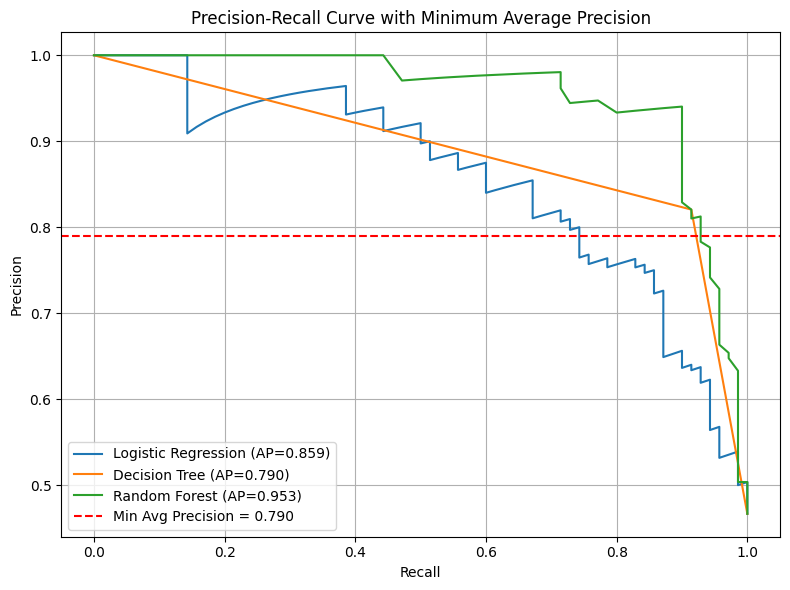

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import precision_recall_curve, average_precision_score

# Step 1: Generate sample binary classification data
X, y = make_classification(n_samples=500, n_features=20, n_classes=2,
                           n_informative=5, random_state=42)

# Step 2: Split into train and test sets
x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Step 3: Train models
lr = LogisticRegression(max_iter=1000).fit(x_train, y_train)
dt = DecisionTreeClassifier().fit(x_train, y_train)
rf = RandomForestClassifier().fit(x_train, y_train)

# Step 4: Collect model scores
def get_scores(model, X):
    if hasattr(model, "predict_proba"):
        return model.predict_proba(X)[:, 1]
    elif hasattr(model, "decision_function"):
        return model.decision_function(X)
    else:
        return model.predict(X)  # fallback

models = {
    "Logistic Regression": get_scores(lr, x_test),
    "Decision Tree": get_scores(dt, x_test),
    "Random Forest": get_scores(rf, x_test)
}

# Step 5: Plot Precision-Recall curves
plt.figure(figsize=(8,6))
min_avg_precision = float('inf')

for name, y_scores in models.items():
    y_scores = np.ravel(y_scores)
    precision, recall, _ = precision_recall_curve(y_test, y_scores)
    avg_precision = average_precision_score(y_test, y_scores)
    
    if avg_precision < min_avg_precision:
        min_avg_precision = avg_precision
    
    plt.plot(recall, precision, label=f"{name} (AP={avg_precision:.3f})")

plt.axhline(y=min_avg_precision, color='red', linestyle='--',
            label=f"Min Avg Precision = {min_avg_precision:.3f}")

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve with Minimum Average Precision")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()
